In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from collections import Counter
import pickle
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from mab.algorithms import exp3_plus_plus, ucb, exp3
from mab.environment.stationary.bernoulli import Bernoulli
from mab.environment.env import Agent
from mab.environment.experiment import Experiment
from mab.environment.plots import plot_regret

In [4]:
from bernoulli_ts1 import BernoulliTS1

In [5]:
with open(f'data/seed{1}_environment_data.pkl', 'rb') as f:
    env1 = pickle.load(f)

In [6]:
n_arms = 3

# Evolution of the process

**Params at iteraton t: 1, 10, 100, 1000, 10_000**

In [7]:
agent_algo = env1.agents[0].algo

In [8]:
print(agent_algo.save_alphas[0])
print(agent_algo.save_betas[0])

[1.0, 1.0, 1.0]
[1.0, 1.0, 1.0]


In [9]:
def plot_beta_dist(alphas, betas):
    thetas = [np.round(a / (a + b), 2) for a, b in zip(alphas, betas)]
    plt.figure()
    for arm in range(n_arms):
        sns.kdeplot(np.random.beta(a=alphas[arm], b=betas[arm], size=10_000), label=f'arm: {arm}')
    plt.title(f'Iteration 1: alphas: {alphas.tolist()}, betas: {betas.tolist()}, thetas: {thetas}')
    plt.legend()

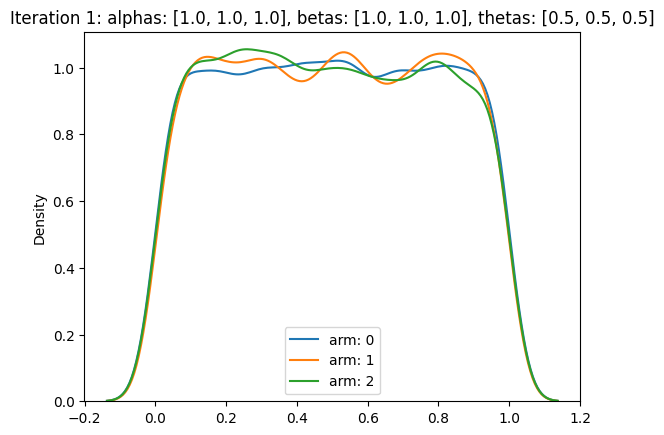

In [10]:
alphas = np.array(agent_algo.save_alphas[0])
betas = np.array(agent_algo.save_betas[0])

plot_beta_dist(alphas, betas)

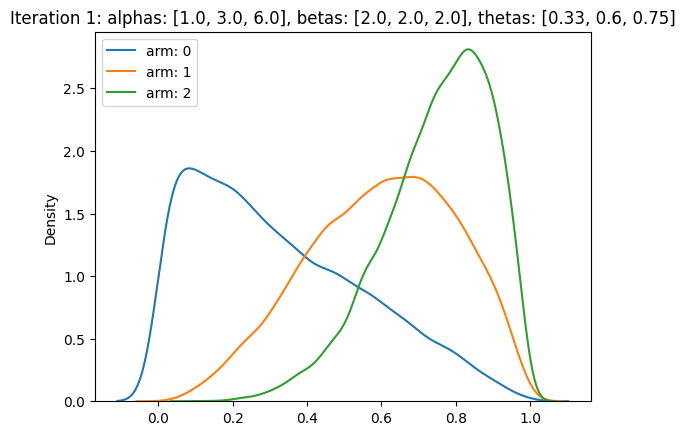

In [11]:
# Iteration 10.
alphas = np.array(agent_algo.save_alphas[10])
betas = np.array(agent_algo.save_betas[10])

plot_beta_dist(alphas, betas)

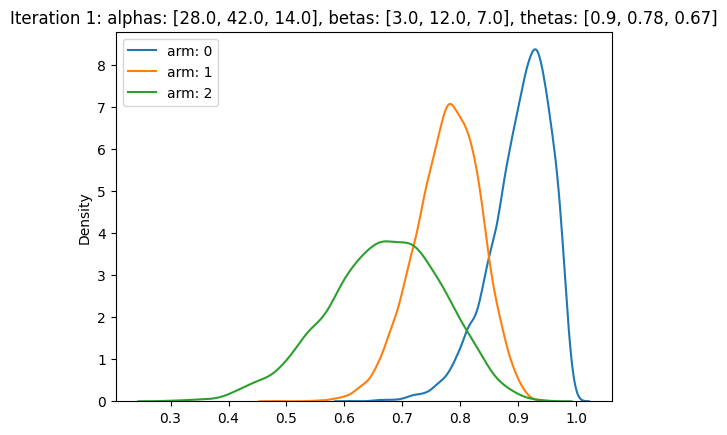

In [12]:
# Iteration 100.
alphas = np.array(agent_algo.save_alphas[100])
betas = np.array(agent_algo.save_betas[100])

plot_beta_dist(alphas, betas)

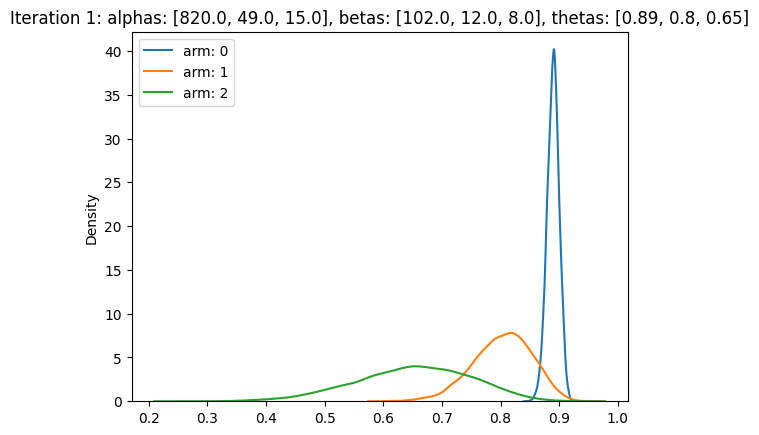

In [13]:
# Iteration 1000.
alphas = np.array(agent_algo.save_alphas[1000])
betas = np.array(agent_algo.save_betas[1000])

plot_beta_dist(alphas, betas)

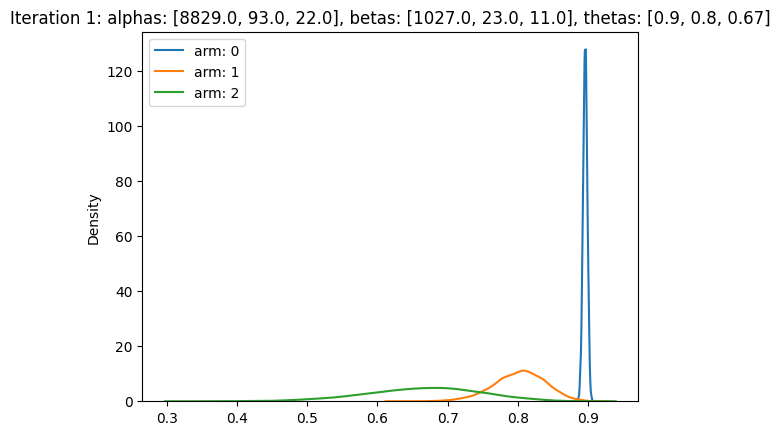

In [14]:
# Iteration 10_000.
alphas = np.array(agent_algo.save_alphas[10_000-1])
betas = np.array(agent_algo.save_betas[10_000-1])

plot_beta_dist(alphas, betas)

# Calculating regret

In [15]:
from mab.environment.stationary import utils

In [16]:
regret = utils.cal_stochastic_regret(env1.env.mean_rewards, env1.agents[0].action_hist)

In [17]:
regret_dict = {'Thompson Sampling (Bernoulli)': regret}

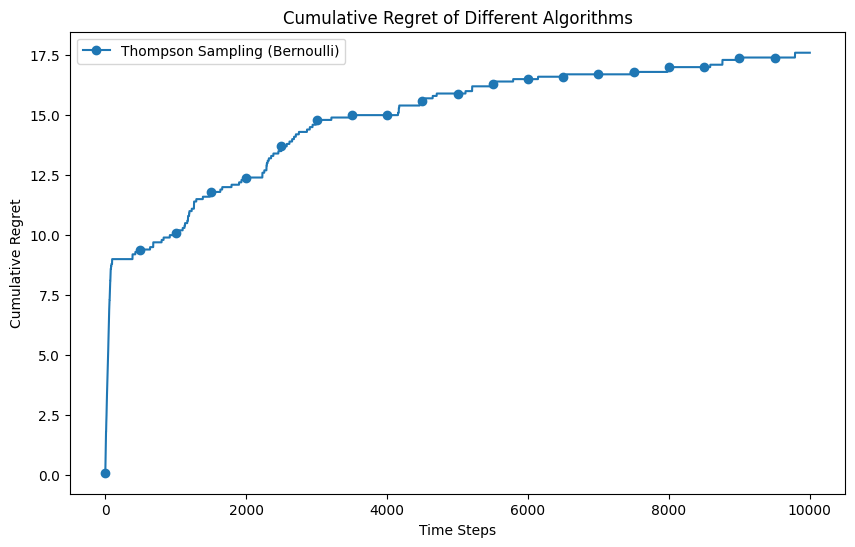

<Figure size 640x480 with 0 Axes>

In [80]:
regret_plot = plot_regret(regret_dict)